# Explicit Euler


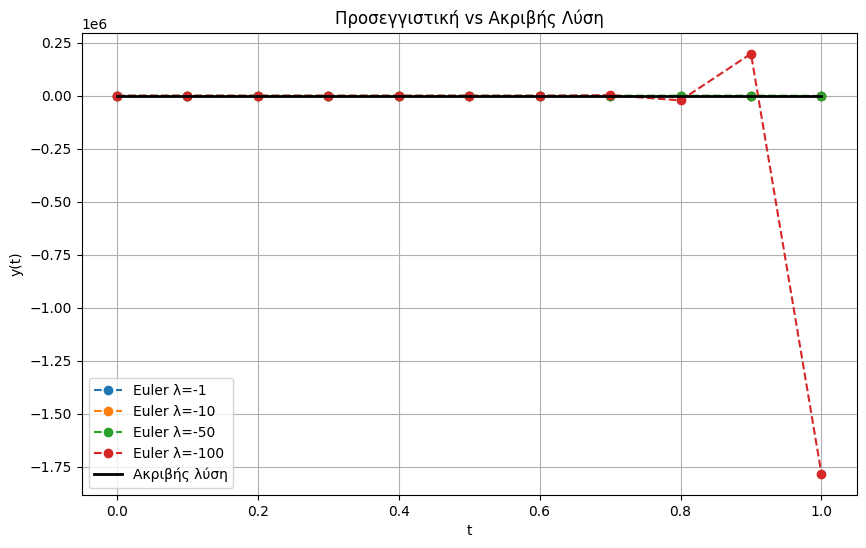

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Explicit Euler
def Exp_Euler(f, t0, T, y0, N):
    tnodes = np.linspace(t0, T, N + 1)
    h = tnodes[1] - tnodes[0]
    yn = np.array(y0)
    yvals = [[v] for v in yn]

    for i in range(N):
        yn = yn + h * f(tnodes[i], yn)
        for j in range(len(yn)):
            yvals[j].append(yn[j])

    return tnodes, np.array(yvals)

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# -------------------------------
# Π.A.T.
# -------------------------------

t0 = 0.0
T  = 1.0
y0 = [1.0]
N  = 10 # N =T-t0/h με h=0,1

lambdas = [-1, -10, -50, -100]

plt.figure(figsize=(10,6))

for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

    t, y = Exp_Euler(f, t0, T, y0, N)

    plt.plot(t, y[0], marker='o', linestyle='--', label=f'Euler λ={lam}')

t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.title("Προσεγγιστική vs Ακριβής Λύση")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
t0 = 0
y0 = [1.0]
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [2, 4, 6, 8, 10]

rows = []

for lam in lambdas:
    # ορισμός f για κάθε λ
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}

        for h in hs:
            N = int(t_val / h)
            t, y = Exp_Euler(f, 0, t_val, y0, N)
            error = abs(y_exact(t_val) - y[0, -1])
            row[f"Error h={h}"] = error

        rows.append(row)

df = pd.DataFrame(rows)
df.style.set_caption("Η άμεση μέθοδος του Euler")
df

print(df.to_latex(index=False, float_format="%.2e"))


\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2 & 4.64e-02 & 2.30e-02 & 1.14e-02 & 4.55e-04 \\
-1 & 4 & 3.91e-02 & 1.92e-02 & 9.54e-03 & 3.79e-04 \\
-1 & 6 & 1.39e-02 & 6.97e-03 & 3.49e-03 & 1.40e-04 \\
-1 & 8 & 5.07e-02 & 2.50e-02 & 1.24e-02 & 4.95e-04 \\
-1 & 10 & 2.83e-02 & 1.39e-02 & 6.87e-03 & 2.72e-04 \\
-10 & 2 & 2.90e-03 & 1.50e-03 & 7.62e-04 & 3.10e-05 \\
-10 & 4 & 7.07e-03 & 3.53e-03 & 1.76e-03 & 7.03e-05 \\
-10 & 6 & 2.98e-03 & 1.43e-03 & 7.03e-04 & 2.76e-05 \\
-10 & 8 & 4.59e-03 & 2.33e-03 & 1.18e-03 & 4.74e-05 \\
-10 & 10 & 6.80e-03 & 3.38e-03 & 1.68e-03 & 6.70e-05 \\
-50 & 2 & 1.11e+09 & 5.51e+03 & 1.27e-04 & 5.19e-06 \\
-50 & 4 & 1.23e+21 & 6.09e+10 & 3.53e-04 & 1.41e-05 \\
-50 & 6 & 1.35e+33 & 6.74e+17 & 1.67e-04 & 6.56e-06 \\
-50 & 8 & 1.48e+45 & 7.45e+24 & 2.14e-04 & 8.66e-06 \\
-50 & 10 & 1.63e+57 & 8.24e+31 & 3.45e-04 & 1.38e-05 \\
-100 & 2 & 6.22e+15 & 3.04e+20 & 1.53e+10 & 2.53e-06 \\
-100 & 4 

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Explicit {\en Euler} method  \\
\end{tabular}
\\
\begin{tabular}{rrrrrr}
\toprule
$\lambda $ & $t$ & error $y(t) - y_n$ & error $y(t) - y_n$ & error $y(t) - y_n$ & error $y(t) - y_n$\\
& & $h=0.1$ & $h= 0.05$ & $h=0.025$ & $h=0.001$ \\
\midrule
-1 & 2 & 4.64e-02 & 2.30e-02 & 1.14e-02 & 4.55e-04 \\
-1 & 4 & 3.91e-02 & 1.92e-02 & 9.54e-03 & 3.79e-04 \\
-1 & 6 & 1.39e-02 & 6.97e-03 & 3.49e-03 & 1.40e-04 \\
-1 & 8 & 5.07e-02 & 2.50e-02 & 1.24e-02 & 4.95e-04 \\
-1 & 10 & 2.83e-02 & 1.39e-02 & 6.87e-03 & 2.72e-04 \\
\midrule
-10 & 2 & 2.90e-03 & 1.50e-03 & 7.62e-04 & 3.10e-05 \\
-10 & 4 & 7.07e-03 & 3.53e-03 & 1.76e-03 & 7.03e-05 \\
-10 & 6 & 2.98e-03 & 1.43e-03 & 7.03e-04 & 2.76e-05 \\
-10 & 8 & 4.59e-03 & 2.33e-03 & 1.18e-03 & 4.74e-05 \\
-10 & 10 & 6.80e-03 & 3.38e-03 & 1.68e-03 & 6.70e-05 \\
\midrule
-50 & 2 & 1.11e+09 & 5.51e+03 & 1.27e-04 & 5.19e-06 \\
-50 & 4 & 1.23e+21 & 6.09e+10 & 3.53e-04 & 1.41e-05 \\
-50 & 6 & 1.35e+33 & 6.74e+17 & 1.67e-04 & 6.56e-06 \\
-50 & 8 & 1.48e+45 & 7.45e+24 & 2.14e-04 & 8.66e-06 \\
-50 & 10 & 1.63e+57 & 8.24e+31 & 3.45e-04 & 1.38e-05 \\
\midrule
-100 & 2 & 6.22e+15 & 3.04e+20 & 1.53e+10 & 2.53e-06 \\
-100 & 4 & 7.56e+34 & 3.68e+44 & 1.87e+24 & 7.06e-06 \\
-100 & 6 & 9.19e+53 & 4.45e+68 & 2.28e+38 & 3.34e-06 \\
-100 & 8 & 1.12e+73 & 5.38e+92 & 2.79e+52 & 4.27e-06 \\
-100 & 10 & 1.36e+92 & 6.50e+116 & 3.41e+66 & 6.90e-06 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}

# Implicit Euler

/tmp/ipython-input-1639730945.py:17: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yn = fsolve(F, yn, (tnodes[i + 1], yn, f, h))


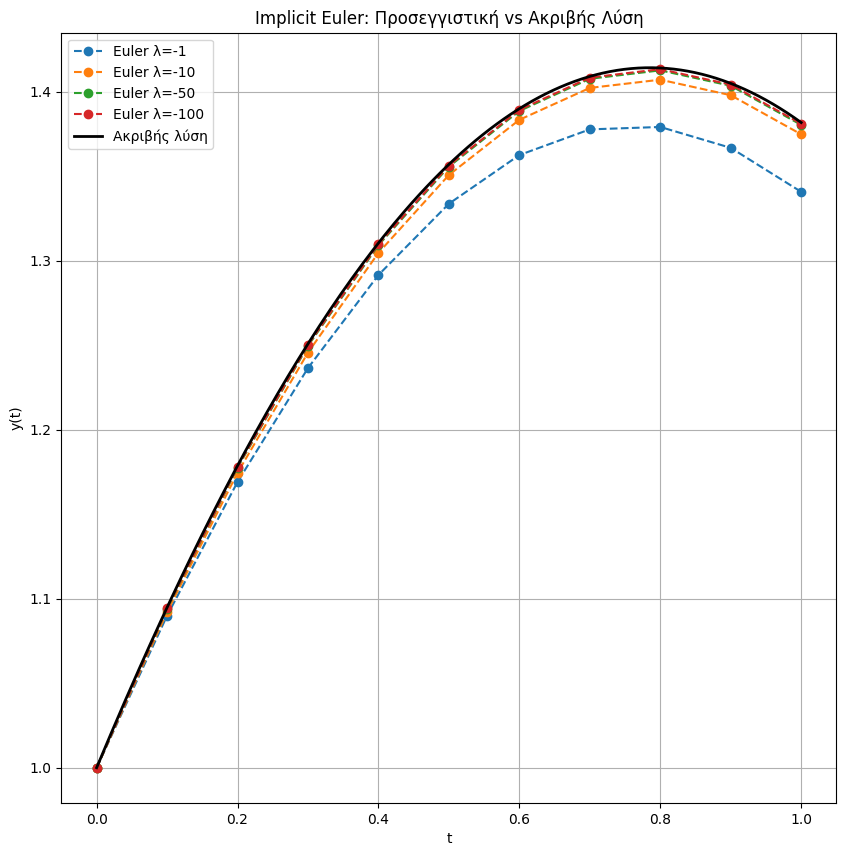

In [3]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt


def F(x,tnew,yold,f,h):
 return x-yold-h*f(tnew,x)

# Implicit Euler
def Imp_Euler(f, t0, T, y0, N):
    tnodes = np.linspace(t0, T, N + 1)
    h = tnodes[1] - tnodes[0]
    yn = np.array(y0)
    yvals = [[v] for v in yn]

    for i in range(N):
        yn = fsolve(F, yn, (tnodes[i + 1], yn, f, h))
        for j in range(len(yn)):
            yvals[j].append(yn[j])

    return tnodes, np.array(yvals)

#--- Ακριβής λύση ---
def y_exact(t):
    return np.cos(t) + np.sin(t)

# -------------------------------
# Π.A.T.
# -------------------------------

t0 = 0.0
T  = 1.0
y0 = [1.0]
N  = 10 # N =T-t0/h με h=0,1

plt.figure(figsize=(10,10))
lambdas = [-1, -10, -50, -100]
for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)
    t, sol = Imp_Euler(f, t0, T, y0, N)
    plt.plot(t,sol[0,:],marker='o', linestyle='--', label=f'Euler λ={lam}')
    #plt.plot(t, y[0], marker='o', linestyle='--', label=f'Euler λ={lam}')

t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.title("Implicit Euler: Προσεγγιστική vs Ακριβής Λύση")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
t0 = 0
y0 = [1.0]
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [2, 4, 6, 8, 10]

rows = []

for lam in lambdas:
    # ορισμός f για κάθε λ
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}

        for h in hs:
            N = int(t_val / h)
            t, y = Imp_Euler(f, 0, t_val, y0, N)
            error = abs(y_exact(t_val) - y[0, -1])
            row[f"Error h={h}"] = error

        rows.append(row)

df = pd.DataFrame(rows)
df.style.set_caption("Η πεπλεγμένη μέθοδος του Euler")
df

print(df.to_latex(index=False, float_format="%.2e"))



/tmp/ipython-input-1639730945.py:17: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yn = fsolve(F, yn, (tnodes[i + 1], yn, f, h))


\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2 & 4.46e-02 & 2.25e-02 & 1.13e-02 & 4.55e-04 \\
-1 & 4 & 3.67e-02 & 1.86e-02 & 9.38e-03 & 3.78e-04 \\
-1 & 6 & 1.40e-02 & 7.00e-03 & 3.50e-03 & 1.40e-04 \\
-1 & 8 & 4.83e-02 & 2.44e-02 & 1.23e-02 & 4.95e-04 \\
-1 & 10 & 2.62e-02 & 1.33e-02 & 6.74e-03 & 2.72e-04 \\
-10 & 2 & 3.29e-03 & 1.60e-03 & 7.86e-04 & 3.10e-05 \\
-10 & 4 & 6.99e-03 & 3.51e-03 & 1.76e-03 & 7.03e-05 \\
-10 & 6 & 2.53e-03 & 1.32e-03 & 6.75e-04 & 2.75e-05 \\
-10 & 8 & 4.88e-03 & 2.41e-03 & 1.19e-03 & 4.74e-05 \\
-10 & 10 & 6.59e-03 & 3.32e-03 & 1.67e-03 & 6.70e-05 \\
-50 & 2 & 5.62e-04 & 2.70e-04 & 1.33e-04 & 5.20e-06 \\
-50 & 4 & 1.41e-03 & 7.06e-04 & 3.53e-04 & 1.41e-05 \\
-50 & 6 & 6.13e-04 & 3.17e-04 & 1.61e-04 & 6.55e-06 \\
-50 & 8 & 9.02e-04 & 4.42e-04 & 2.19e-04 & 8.67e-06 \\
-50 & 10 & 1.36e-03 & 6.85e-04 & 3.43e-04 & 1.38e-05 \\
-100 & 2 & 2.75e-04 & 1.32e-04 & 6.47e-05 & 2.53e-06 \\
-100 & 4 

\begin{tabular}{c}
The Implicit {\en Euler} method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 4.46e-02 & 2.25e-02 & 1.13e-02 & 4.55e-04 \\
-1 & 4 & 3.67e-02 & 1.86e-02 & 9.38e-03 & 3.78e-04 \\
-1 & 6 & 1.40e-02 & 7.00e-03 & 3.50e-03 & 1.40e-04 \\
-1 & 8 & 4.83e-02 & 2.44e-02 & 1.23e-02 & 4.95e-04 \\
-1 & 10 & 2.62e-02 & 1.33e-02 & 6.74e-03 & 2.72e-04 \\
\midrule
-10 & 2 & 3.29e-03 & 1.60e-03 & 7.86e-04 & 3.10e-05 \\
-10 & 4 & 6.99e-03 & 3.51e-03 & 1.76e-03 & 7.03e-05 \\
-10 & 6 & 2.53e-03 & 1.32e-03 & 6.75e-04 & 2.75e-05 \\
-10 & 8 & 4.88e-03 & 2.41e-03 & 1.19e-03 & 4.74e-05 \\
-10 & 10 & 6.59e-03 & 3.32e-03 & 1.67e-03 & 6.70e-05 \\
\midrule
-50 & 2 & 5.62e-04 & 2.70e-04 & 1.33e-04 & 5.20e-06 \\
-50 & 4 & 1.41e-03 & 7.06e-04 & 3.53e-04 & 1.41e-05 \\
-50 & 6 & 6.13e-04 & 3.17e-04 & 1.61e-04 & 6.55e-06 \\
-50 & 8 & 9.02e-04 & 4.42e-04 & 2.19e-04 & 8.67e-06 \\
-50 & 10 & 1.36e-03 & 6.85e-04 & 3.43e-04 & 1.38e-05 \\
\midrule
-100 & 2 & 2.75e-04 & 1.32e-04 & 6.47e-05 & 2.53e-06 \\
-100 & 4 & 7.06e-04 & 3.53e-04 & 1.76e-04 & 7.06e-06 \\
-100 & 6 & 3.13e-04 & 1.62e-04 & 8.22e-05 & 3.34e-06 \\
-100 & 8 & 4.46e-04 & 2.18e-04 & 1.08e-04 & 4.28e-06 \\
-100 & 10 & 6.84e-04 & 3.44e-04 & 1.72e-04 & 6.90e-06 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}

# (γ) Trapezoid Method


/tmp/ipython-input-1654168578.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yn[i+1] = fsolve(F, yold, args=(tnew, told, yold, f, h, th))
/tmp/ipython-input-1654168578.py:18: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yn[i+1] = fsolve(F, yold, args=(tnew, told, yold, f, h, th))


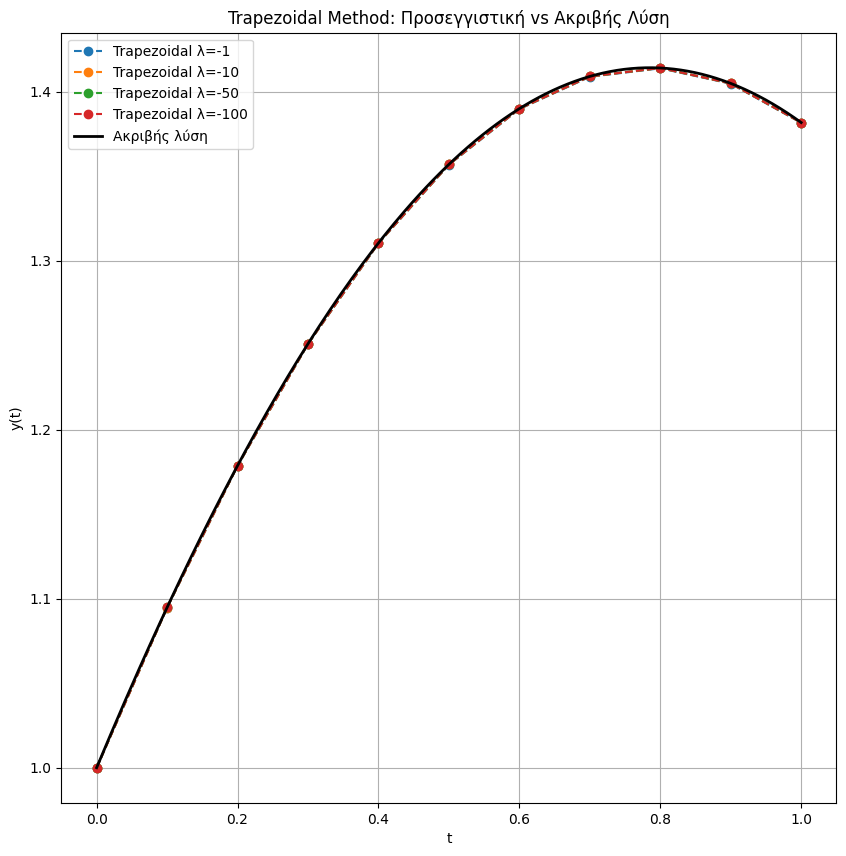

In [5]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

def F(x, tnew, told, yold, f, h, th):
    return x - yold - h * ((1 - th) * f(told, yold) + th * f(tnew, x))

def trapezoidalmethod(f, t0, T, y0, N, th=0.5):
    tnodes = np.linspace(t0, T, N+1)
    h = tnodes[1] - tnodes[0]
    yn = np.zeros(N+1)
    yn[0] = y0

    for i in range(N):
        told = tnodes[i]
        tnew = tnodes[i+1]
        yold = yn[i]
        yn[i+1] = fsolve(F, yold, args=(tnew, told, yold, f, h, th))

    return tnodes, yn

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# -------------------------------
# Π.A.T.
# -------------------------------

t0 = 0.0
T  = 1.0
y0 = 1.0
N  = 10 # N =T-t0/h με h=0,1

plt.figure(figsize=(10,10))
lambdas = [-1, -10, -50, -100]

for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)
    t, sol = trapezoidalmethod(f, t0, T, y0, N)
    plt.plot(t, sol, marker='o', linestyle='--', label=f'Trapezoidal λ={lam}')

# Ακριβής λύση για σύγκριση
t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.title("Trapezoidal Method: Προσεγγιστική vs Ακριβής Λύση")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

t0 = 0
y0 = 1.0
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [2, 4, 6, 8, 10]

rows = []

for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}

        for h in hs:
            N = int(t_val / h)
            t, y = trapezoidalmethod(f, 0, t_val, y0, N)
            error = abs(y_exact(t_val) - y[-1])
            row[f"Error h={h}"] = error

        rows.append(row)

df = pd.DataFrame(rows)
df.style.set_caption("Η μέθοδος Trapezoidal")
print(df.to_latex(index=False, float_format="%.2e"))

/tmp/ipython-input-1654168578.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yn[i+1] = fsolve(F, yold, args=(tnew, told, yold, f, h, th))
/tmp/ipython-input-1654168578.py:18: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yn[i+1] = fsolve(F, yold, args=(tnew, told, yold, f, h, th))


\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2 & 4.59e-04 & 1.15e-04 & 2.87e-05 & 4.60e-08 \\
-1 & 4 & 5.61e-04 & 1.40e-04 & 3.50e-05 & 5.60e-08 \\
-1 & 6 & 7.98e-04 & 2.00e-04 & 4.99e-05 & 7.98e-08 \\
-1 & 8 & 1.21e-04 & 3.04e-05 & 7.59e-06 & 1.22e-08 \\
-1 & 10 & 7.00e-04 & 1.75e-04 & 4.37e-05 & 6.99e-08 \\
-10 & 2 & 1.05e-04 & 2.63e-05 & 6.58e-06 & 1.05e-08 \\
-10 & 4 & 3.14e-06 & 7.82e-07 & 1.95e-07 & 3.13e-10 \\
-10 & 6 & 1.08e-04 & 2.70e-05 & 6.74e-06 & 1.08e-08 \\
-10 & 8 & 8.68e-05 & 2.17e-05 & 5.42e-06 & 8.67e-09 \\
-10 & 10 & 3.58e-05 & 8.94e-06 & 2.23e-06 & 3.58e-09 \\
-50 & 2 & 2.19e-05 & 5.48e-06 & 1.37e-06 & 2.19e-09 \\
-50 & 4 & 1.25e-06 & 3.12e-07 & 7.80e-08 & 1.25e-10 \\
-50 & 6 & 2.09e-05 & 5.22e-06 & 1.30e-06 & 2.09e-09 \\
-50 & 8 & 1.86e-05 & 4.66e-06 & 1.16e-06 & 1.86e-09 \\
-50 & 10 & 5.38e-06 & 1.34e-06 & 3.36e-07 & 5.38e-10 \\
-100 & 2 & 1.10e-05 & 2.75e-06 & 6.88e-07 & 1.10e-09 \\
-100 & 4 

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Trapezoidal Method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 4.59e-04 & 1.15e-04 & 2.87e-05 & 4.60e-08 \\
-1 & 4 & 5.61e-04 & 1.40e-04 & 3.50e-05 & 5.60e-08 \\
-1 & 6 & 7.98e-04 & 2.00e-04 & 4.99e-05 & 7.98e-08 \\
-1 & 8 & 1.21e-04 & 3.04e-05 & 7.59e-06 & 1.22e-08 \\
-1 & 10 & 7.00e-04 & 1.75e-04 & 4.37e-05 & 6.99e-08 \\
\midrule
-10 & 2 & 1.05e-04 & 2.63e-05 & 6.58e-06 & 1.05e-08 \\
-10 & 4 & 3.14e-06 & 7.82e-07 & 1.95e-07 & 3.13e-10 \\
-10 & 6 & 1.08e-04 & 2.70e-05 & 6.74e-06 & 1.08e-08 \\
-10 & 8 & 8.68e-05 & 2.17e-05 & 5.42e-06 & 8.67e-09 \\
-10 & 10 & 3.58e-05 & 8.94e-06 & 2.23e-06 & 3.58e-09 \\
\midrule
-50 & 2 & 2.19e-05 & 5.48e-06 & 1.37e-06 & 2.19e-09 \\
-50 & 4 & 1.25e-06 & 3.12e-07 & 7.80e-08 & 1.25e-10 \\
-50 & 6 & 2.09e-05 & 5.22e-06 & 1.30e-06 & 2.09e-09 \\
-50 & 8 & 1.86e-05 & 4.66e-06 & 1.16e-06 & 1.86e-09 \\
-50 & 10 & 5.38e-06 & 1.34e-06 & 3.36e-07 & 5.38e-10 \\
\midrule
-100 & 2 & 1.10e-05 & 2.75e-06 & 6.88e-07 & 1.10e-09 \\
-100 & 4 & 7.43e-07 & 1.86e-07 & 4.64e-08 & 7.42e-11 \\
-100 & 6 & 1.04e-05 & 2.60e-06 & 6.49e-07 & 1.04e-09 \\
-100 & 8 & 9.40e-06 & 2.35e-06 & 5.87e-07 & 9.39e-10 \\
-100 & 10 & 2.58e-06 & 6.44e-07 & 1.61e-07 & 2.57e-10 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}


 # (ε) Adams-Bashforth 3

/tmp/ipython-input-2016969733.py:16: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  y_next = fsolve(F, y_n)


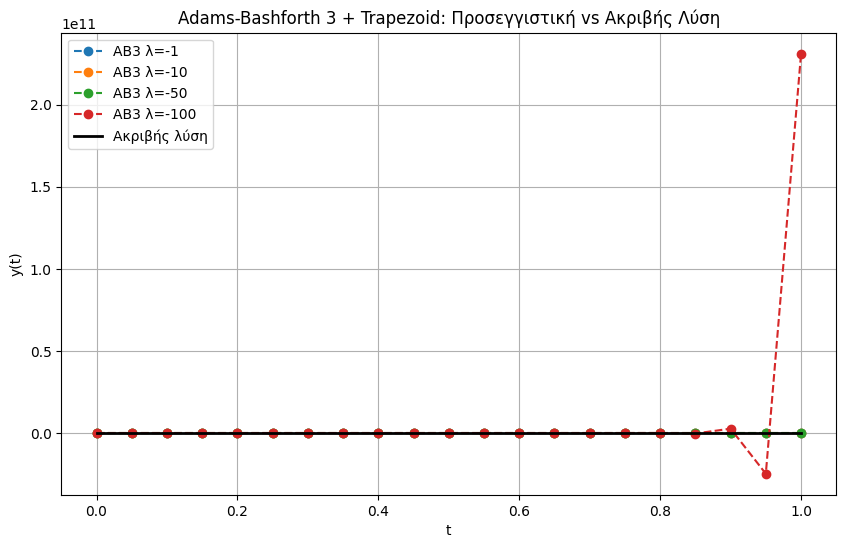

In [7]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

# Συνάρτηση f(t,y)
def f(t, y, lam):
    return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Trapezoid step
def trapezoid_step(f, t_n, y_n, h, lam):
    F = lambda x: x - y_n - h/2*(f(t_n, y_n, lam) + f(t_n + h, x, lam))
    y_next = fsolve(F, y_n)
    return y_next[0]

# AB3 + Trapezoid solver
def AB3_trapezoid(lam, h, T):
    N = int(T/h)
    y0 = 1.0
    t0 = 0.0

    # Πρώτα δύο βήματα με trapezoid
    y1 = trapezoid_step(f, t0, y0, h, lam)
    t1 = t0 + h
    y2 = trapezoid_step(f, t1, y1, h, lam)
    t2 = t1 + h

    y_list = [y0, y1, y2]
    t_list = [t0, t1, t2]
    f_list = [f(t0, y0, lam), f(t1, y1, lam), f(t2, y2, lam)]

    # AB3
    for n in range(2, N):
        y_new = y_list[-1] + h*(23/12*f_list[-1] - 4/3*f_list[-2] + 5/12*f_list[-3])
        t_new = t_list[-1] + h
        y_list.append(y_new)
        t_list.append(t_new)
        f_list.append(f(t_new, y_new, lam))

    t_list = np.array(t_list)
    y_list = np.array(y_list)
    y_exact_list = y_exact(t_list)
    error = np.abs(y_list - y_exact_list)
    return t_list, y_list, y_exact_list, error

# -------------------------------
# Παράμετροι
# -------------------------------
t0 = 0.0
T  = 1.0
y0 = 1.0
h = 0.05
lambdas = [-1, -10, -50, -100]

plt.figure(figsize=(10,6))
for lam in lambdas:
    t_list, y_num, y_ex, err = AB3_trapezoid(lam, h, T)
    plt.plot(t_list, y_num, marker='o', linestyle='--', label=f'AB3 λ={lam}')

# Ακριβής λύση
t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Adams-Bashforth 3 + Trapezoid: Προσεγγιστική vs Ακριβής Λύση')
plt.grid(True)
plt.legend()
plt.show()

#to l = -100 einai ektos diasthmatos gia ayto exei megalh apoklhsh
                     # −0.545 < hλ < 0


In [8]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
y0 = 1.0
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [0.2, 0.4, 0.6, 0.8, 1.0]
rows = []

for lam in lambdas:
    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}
        for h in hs:
            N = int(t_val / h)
            t_list, y_num, y_ex, err = AB3_trapezoid(lam, h, t_val)
            error = np.abs(y_num[-1] - y_exact(t_val))
            row[f"Error h={h}"] = error
        rows.append(row)

# Δημιουργία DataFrame
df = pd.DataFrame(rows)
df.style.set_caption("Σφάλματα με Adams-Bashforth 3 + Trapezoid")
print(df.to_latex(index=False, float_format="%.2e"))

/tmp/ipython-input-2016969733.py:16: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  y_next = fsolve(F, y_n)


\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2.00e-01 & 1.35e-04 & 2.19e-05 & 3.02e-06 & 2.10e-10 \\
-1 & 4.00e-01 & 1.91e-04 & 2.82e-05 & 3.78e-06 & 2.57e-10 \\
-1 & 6.00e-01 & 3.32e-02 & 1.48e-02 & 6.96e-03 & 3.03e-10 \\
-1 & 8.00e-01 & 2.94e-04 & 4.01e-05 & 5.20e-06 & 3.43e-10 \\
-1 & 1.00e+00 & 3.37e-04 & 4.48e-05 & 5.75e-06 & 3.77e-10 \\
-10 & 2.00e-01 & 6.42e-05 & 9.64e-06 & 9.65e-07 & 5.90e-11 \\
-10 & 4.00e-01 & 5.96e-05 & 7.06e-06 & 7.64e-07 & 4.91e-11 \\
-10 & 6.00e-01 & 3.30e-02 & 1.48e-02 & 6.95e-03 & 5.10e-11 \\
-10 & 8.00e-01 & 1.22e-04 & 7.03e-06 & 8.20e-07 & 5.26e-11 \\
-10 & 1.00e+00 & 2.77e-04 & 6.94e-06 & 8.21e-07 & 5.24e-11 \\
-50 & 2.00e-01 & 1.03e-05 & 1.88e-06 & 2.13e-05 & 8.72e-12 \\
-50 & 4.00e-01 & 8.31e-04 & 1.49e-03 & 1.35e-02 & 9.74e-12 \\
-50 & 6.00e-01 & 4.08e-02 & 1.57e-01 & 3.86e+00 & 1.04e-11 \\
-50 & 8.00e-01 & 6.35e+00 & 2.85e+02 & 5.54e+03 & 1.06e-11 \\
-50 & 1.00e+00 & 5.52e+02

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Adams-Bashforth 3 + Trapezoid Method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 1.35e-04 & 2.19e-05 & 3.02e-06 & 2.10e-10 \\
-1 & 4 & 1.91e-04 & 2.82e-05 & 3.78e-06 & 2.57e-10 \\
-1 & 6 & 3.32e-02 & 1.48e-02 & 6.96e-03 & 3.03e-10 \\
-1 & 8 & 2.94e-04 & 4.01e-05 & 5.20e-06 & 3.43e-10 \\
-1 & 10 & 3.37e-04 & 4.48e-05 & 5.75e-06 & 3.77e-10 \\
\midrule
-10 & 2 & 6.42e-05 & 9.64e-06 & 9.65e-07 & 5.90e-11 \\
-10 & 4 & 5.96e-05 & 7.06e-06 & 7.64e-07 & 4.91e-11 \\
-10 & 6 & 3.30e-02 & 1.48e-02 & 6.95e-03 & 5.10e-11 \\
-10 & 8 & 1.22e-04 & 7.03e-06 & 8.20e-07 & 5.26e-11 \\
-10 & 10 & 2.77e-04 & 6.94e-06 & 8.21e-07 & 5.24e-11 \\
\midrule
-50 & 2 & 1.03e-05 & 1.88e-06 & 2.13e-05 & 8.72e-12 \\
-50 & 4 & 8.31e-04 & 1.49e-03 & 1.35e-02 & 9.74e-12 \\
-50 & 6 & 4.08e-02 & 1.57e-01 & 3.86e+00 & 1.04e-11 \\
-50 & 8 & 6.35e+00 & 2.85e+02 & 5.54e+03 & 1.06e-11 \\
-50 & 10 & 5.52e+02 & 1.24e+05 & 3.54e+06 & 1.04e-11 \\
\midrule
-100 & 2 & 2.87e-06 & 7.03e-05 & 1.61e-04 & 4.39e-12 \\
-100 & 4 & 2.99e-03 & 5.36e-01 & 3.06e+01 & 4.89e-12 \\
-100 & 6 & 8.94e-02 & 4.35e+02 & 1.27e+06 & 5.20e-12 \\
-100 & 8 & 3.80e+02 & 3.06e+07 & 1.11e+12 & 5.30e-12 \\
-100 & 10 & 1.36e+05 & 2.31e+11 & 2.11e+17 & 5.19e-12 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}


# (δ) Adams-Bashforth 2

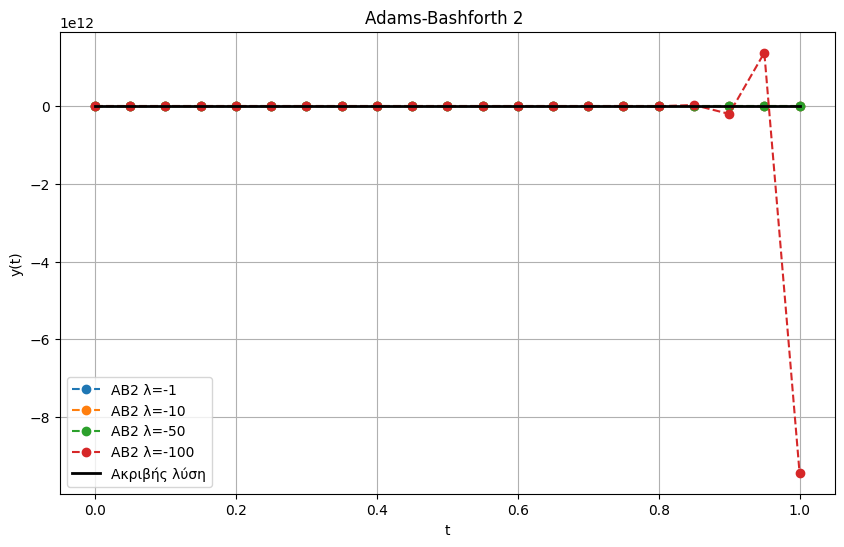

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Συνάρτηση f(t, y)
def f(t, y, lam):
    return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Μέθοδος Adams-Bashforth 2ης τάξης
def AB2(lam, h, T):
    N = int(T/h)
    y0 = 1.0
    t0 = 0.0

    # Πρώτο βήμα με Euler
    y1 = y0 + h*f(t0, y0, lam)
    t1 = t0 + h

    y_list = [y0, y1]
    t_list = [t0, t1]
    f_list = [f(t0, y0, lam), f(t1, y1, lam)]

    # Υπόλοιπα βήματα AB2
    for n in range(1, N):
        y_new = y_list[-1] + h/2*(3*f_list[-1] - f_list[-2])
        t_new = t_list[-1] + h
        y_list.append(y_new)
        t_list.append(t_new)
        f_list.append(f(t_new, y_new, lam))

    t_list = np.array(t_list)
    y_list = np.array(y_list)
    y_exact_list = y_exact(t_list)
    error = np.abs(y_list - y_exact_list)
    return t_list, y_list, y_exact_list, error

# -------------------------------
# Παράμετροι και διάγραμμα
# -------------------------------
t0 = 0.0
T = 1.0
h = 0.05
lambdas = [-1, -10, -50, -100]

plt.figure(figsize=(10,6))
for lam in lambdas:
    t_list, y_num, y_ex, err = AB2(lam, h, T)
    plt.plot(t_list, y_num, marker='o', linestyle='--', label=f'AB2 λ={lam}')

# Ακριβής λύση
t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Adams-Bashforth 2 ')
plt.grid(True)
plt.legend()
plt.show()


#to l = -100 einai ektos diasthmatos gia ayto exei megalh apoklhsh
                     # −1 < hλ < 0

In [10]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
y0 = 1.0
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [0.2, 0.4, 0.6, 0.8, 1.0]  # Προσαρμοσμένα για T=1
rows = []

for lam in lambdas:
    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}
        for h in hs:
            N = int(t_val / h)
            t_list, y_num, y_ex, err = AB2(lam, h, t_val)
            error = np.abs(y_num[-1] - y_exact(t_val))
            row[f"Error h={h}"] = error
        rows.append(row)

# Δημιουργία DataFrame
df = pd.DataFrame(rows)
df.style.set_caption("Σφάλματα με Adams-Bashforth 3 + Trapezoid")
print(df.to_latex(index=False, float_format="%.2e"))

\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2.00e-01 & 4.77e-03 & 1.20e-03 & 2.99e-04 & 4.77e-07 \\
-1 & 4.00e-01 & 4.46e-03 & 1.11e-03 & 2.76e-04 & 4.40e-07 \\
-1 & 6.00e-01 & 2.87e-02 & 1.37e-02 & 6.70e-03 & 3.90e-07 \\
-1 & 8.00e-01 & 3.43e-03 & 8.40e-04 & 2.08e-04 & 3.28e-07 \\
-1 & 1.00e+00 & 2.74e-03 & 6.64e-04 & 1.63e-04 & 2.56e-07 \\
-10 & 2.00e-01 & 2.20e-03 & 2.50e-04 & 6.65e-05 & 9.90e-08 \\
-10 & 4.00e-01 & 2.83e-03 & 1.02e-04 & 2.37e-05 & 3.57e-08 \\
-10 & 6.00e-01 & 2.93e-02 & 1.47e-02 & 6.94e-03 & 1.77e-08 \\
-10 & 8.00e-01 & 3.21e-03 & 1.77e-05 & 3.78e-06 & 5.17e-09 \\
-10 & 1.00e+00 & 3.34e-03 & 1.23e-05 & 3.64e-06 & 6.67e-09 \\
-50 & 2.00e-01 & 3.32e-02 & 3.48e-02 & 1.80e-03 & 6.73e-09 \\
-50 & 4.00e-01 & 1.57e+00 & 3.42e+00 & 1.89e-02 & 4.65e-09 \\
-50 & 6.00e-01 & 1.07e+01 & 1.07e+02 & 1.41e-01 & 2.41e-09 \\
-50 & 8.00e-01 & 3.49e+03 & 3.29e+04 & 2.07e+00 & 7.06e-11 \\
-50 & 1.00e+00 & 1.64e+05

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Adams-Bashforth 2 + Euler Method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 4.77e-03 & 1.20e-03 & 2.99e-04 & 4.77e-07 \\
-1 & 4 & 4.46e-03 & 1.11e-03 & 2.76e-04 & 4.40e-07 \\
-1 & 6 & 2.87e-02 & 1.37e-02 & 6.70e-03 & 3.90e-07 \\
-1 & 8 & 3.43e-03 & 8.40e-04 & 2.08e-04 & 3.28e-07 \\
-1 & 10 & 2.74e-03 & 6.64e-04 & 1.63e-04 & 2.56e-07 \\
\midrule
-10 & 2 & 2.20e-03 & 2.50e-04 & 6.65e-05 & 9.90e-08 \\
-10 & 4 & 2.83e-03 & 1.02e-04 & 2.37e-05 & 3.57e-08 \\
-10 & 6 & 2.93e-02 & 1.47e-02 & 6.94e-03 & 1.77e-08 \\
-10 & 8 & 3.21e-03 & 1.77e-05 & 3.78e-06 & 5.17e-09 \\
-10 & 10 & 3.34e-03 & 1.23e-05 & 3.64e-06 & 6.67e-09 \\
\midrule
-50 & 2. & 3.32e-02 & 3.48e-02 & 1.80e-03 & 6.73e-09 \\
-50 & 4 & 1.57e+00 & 3.42e+00 & 1.89e-02 & 4.65e-09 \\
-50 & 6 & 1.07e+01 & 1.07e+02 & 1.41e-01 & 2.41e-09 \\
-50 & 8 & 3.49e+03 & 3.29e+04 & 2.07e+00 & 7.06e-11 \\
-50 & 10 & 1.64e+05 & 3.23e+06 & 2.17e+01 & 2.27e-09 \\
\midrule
-100 & 2 & 7.19e-02 & 3.88e-01 & 8.51e-01 & 3.31e-09 \\
-100 & 4 & 1.48e+01 & 8.62e+02 & 8.19e+03 & 2.27e-09 \\
-100 & 6 & 2.13e+02 & 2.79e+05 & 2.51e+07 & 1.15e-09 \\
-100 & 8 & 6.28e+05 & 4.25e+09 & 7.59e+11 & 2.36e-11 \\
-100 & 10 & 1.29e+08 & 9.43e+12 & 7.31e+15 & 1.19e-09 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}

#(η) Η βελτιωμένη μέθοδος του Euler

Ένας εναλλακτικός τρόπος περιγραφής του βήματος τησ γενικής μεθόδου RK με q
ενδιάμεσα στάδια ειναι o εξής : θέτουμε $ k^{(n,i)} = f(t^{(n,i)},y^{(n,i)}) $ ,οπότε οι σχέσεις γράφονται στη μορφή

\begin{equation}
\label{pstiff}
\left\{
\begin{aligned}
k^{(n,i)} &= f\!\left(
t^{(n,i)},
\, y^n + h \sum_{j=1}^{q} a_{ij} \, k^{(n,j)}
\right),
\qquad i = 1, \dots, q, \\[1ex]
y^{n+1} &:= y^n + h \sum_{i=1}^{q} b_i \, k^{(n,i)} .
\end{aligned}
\right.
\end{equation}

Η εφαρμογή μιας μεθόδου RK που αντιστοίχει στο μητρώο για την προσέγγιση της
λύσης ενός προβλήματος αρχικών τιμών για ένα σύστημα Δ.Ε

\begin{equation}
\label{pstiff}
\left\{
\begin{aligned}
y'(t) &= f(t,y(t)), \qquad a \le t \le b, \\
y(a)  &= y_0 .
\end{aligned}
\right.
\end{equation}


$ y : [a,b] \to \mathbb{R}^m  $ είναι άμεση : Όλοι οι τύποι , παραμένουν οι ίδιοι, με τη διαφορά ότι σε αυτήν την περίπτώση $ y^0 ,y^n ,y^{(n,i)}, k{(n,i)}  \in \mathbb{R}^m $.Το μη γραμμικό σύστημα αποτελείται τώρα από mq εξίσωσεις και mq αγνώστους , τις συνιστώσες των q διανυσμάτων $y^{(n,i)} \in \mathbb{R}^m $,που ορίζονται μονοσήμαντα για αρκετά μικρό h.

η μεθοδος RK που περιγρλαφετε από το μητρώο παράγει συνεπώς τισ προσεγγίσεις $y^o,....,y^N$ που δίνονται μέσω των σχέσεων

\begin{equation}
\label{RKmethod}
\left\{
\begin{aligned}
y^0 &:= y_0, \\[1ex]
y^{(n,i)} &= y^n + h \sum_{j=1}^{q} a_{ij}\,
f\!\left(t^{(n,j)},\, y^{(n,j)}\right),
\qquad 1 \le i \le q, \\[1ex]
y^{n+1} &:= y^n + h \sum_{i=1}^{q} b_i\,
f\!\left(t^{(n,i)},\, y^{(n,i)}\right),
\qquad n = 0,\dots, N-1 .
\end{aligned}
\right.
\end{equation}


ΑΥΤΟ ΚΑΤΩ ΑΝ ΤΟ ΑΝΤΙΓΡΑΨΕΙΣ ΕΤΣΙ ΚΑΤΕΥΘΕΙΑΝ ΣΤΟ ΛΑΤΕΧ ΣΤΟ ΕΚΤΙΠΩΝΕΙ ΟΠΩΣ ΠΡΕΠΕΙ

\subsection*{Βελτιωμένη μέθοδος Euler ως Runge--Kutta}

Η βελτιωμένη μέθοδος του Euler (μέθοδος Heun) περιγράφεται από το ταμπλό
\[
\begin{array}{c|cc}
0 & 0 & 0 \\
1 & 1 & 0 \\
\hline
  & \tfrac{1}{2} & \tfrac{1}{2}
\end{array}
\]
και αντιστοιχεί στη Runge--Kutta μέθοδο:
\[
\begin{aligned}
k_1 &= f(t_n, y_n), \\
k_2 &= f(t_n + h,\, y_n + h k_1), \\
y_{n+1} &= y_n + \frac{h}{2}\,(k_1 + k_2).
\end{aligned}
\]

Άρα ο κώδικας είναι

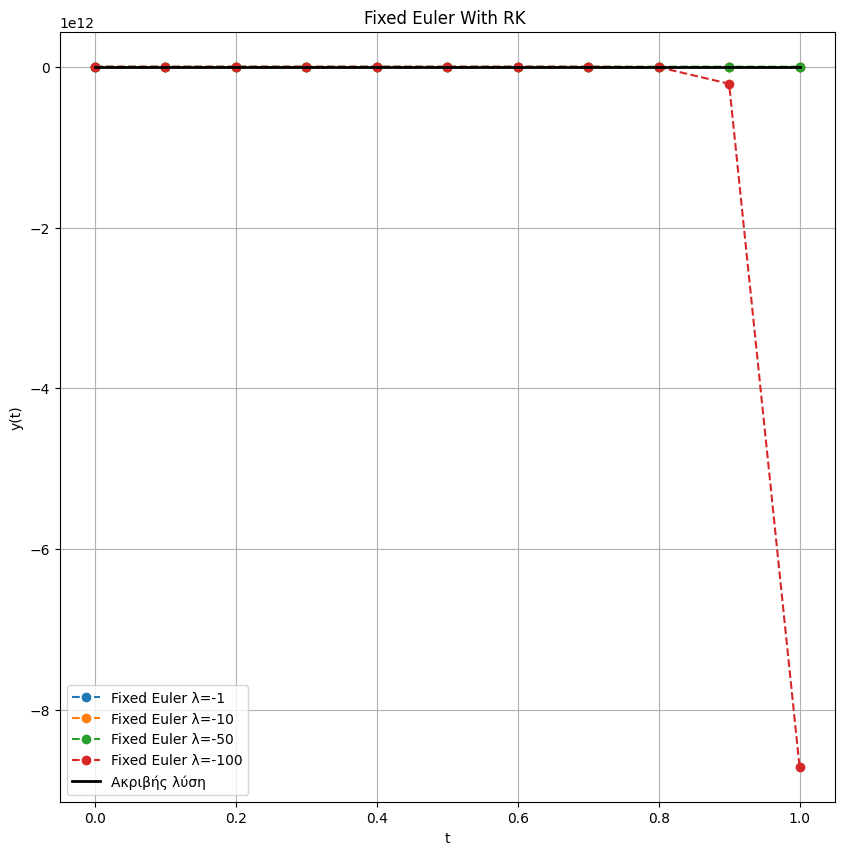

In [18]:
import numpy as np
import matplotlib.pyplot as plt


# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

def Fixed_Euler(f, t0, T, y0, N):

  tnodes = np.linspace(t0,T,N+1) # Uniform partition with N nodes
  h = tnodes[1] - tnodes[0]
  #print(tnodes)
  yn = np.zeros(N+1)
  yn[0] = y0

  for i in range(N):
    tn = tnodes[i]
    kn1 = f(tn, yn[i]) #kn1 = f(t^n, y^n)
    kn2 = f(tn + h, yn[i]+ h*kn1)
    yn[i+1] = yn[i] + (h/2)*(kn1 + kn2)

  return tnodes, yn

# -------------------------------
# Παράμετροι και διάγραμμα
# -------------------------------
t0 = 0.0
T  = 1.0
y0 = 1.0
N  = 10 # N =T-t0/h με h=0,1
lambdas = [-1, -10, -50, -100]


plt.figure(figsize=(10,10))
for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)
    t_list, y_num = Fixed_Euler(f, t0, T, y0, N)
    plt.plot(t_list, y_num, marker='o', linestyle='--', label=f'Fixed Euler λ={lam}')
# Ακριβής λύση
t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Fixed Euler With RK ')
plt.grid(True)
plt.legend()
plt.show()

#to l = -100 einai ektos diasthmatos gia ayto exei megalh apoklhsh
                     # −2 < hλ < 0

In [19]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
y0 = 1.0
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [0.2, 0.4, 0.6, 0.8, 1.0]  # Προσαρμοσμένα για T=1
rows = []

for lam in lambdas:
    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}
        for h in hs:
            N = int(t_val / h)
            t_list, y_num = Fixed_Euler(f, t0, T, y0, N)
            error = np.abs(y_num[-1] - y_exact(t_val))
            row[f"Error h={h}"] = error
        rows.append(row)

# Δημιουργία DataFrame
df = pd.DataFrame(rows)
df.style.set_caption("Σφάλματα με Fixed Euler with RK")
print(df.to_latex(index=False, float_format="%.2e"))

\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2.00e-01 & 1.32e-01 & 1.87e-01 & 1.99e-01 & 2.03e-01 \\
-1 & 4.00e-01 & 5.55e-02 & 6.76e-02 & 7.04e-02 & 7.13e-02 \\
-1 & 6.00e-01 & 1.81e-02 & 1.01e-02 & 8.64e-03 & 8.21e-03 \\
-1 & 8.00e-01 & 3.60e-02 & 3.32e-02 & 3.25e-02 & 3.23e-02 \\
-1 & 1.00e+00 & 2.36e-03 & 5.75e-04 & 1.42e-04 & 2.25e-07 \\
-10 & 2.00e-01 & 3.34e+00 & 2.59e-01 & 1.89e-01 & 2.03e-01 \\
-10 & 4.00e-01 & 3.90e-01 & 5.69e-02 & 6.93e-02 & 7.13e-02 \\
-10 & 6.00e-01 & 1.38e-01 & 1.35e-02 & 9.05e-03 & 8.21e-03 \\
-10 & 8.00e-01 & 4.67e-02 & 3.43e-02 & 3.27e-02 & 3.23e-02 \\
-10 & 1.00e+00 & 6.97e-03 & 1.16e-03 & 2.49e-04 & 3.50e-07 \\
-50 & 2.00e-01 & 5.20e+02 & 6.37e+04 & 3.35e+06 & 2.03e-01 \\
-50 & 4.00e-01 & 6.37e+04 & 3.35e+06 & 2.06e+04 & 7.13e-02 \\
-50 & 6.00e-01 & 3.11e+05 & 2.39e+06 & 3.45e-01 & 8.21e-03 \\
-50 & 8.00e-01 & 3.35e+06 & 2.06e+04 & 3.38e-02 & 3.23e-02 \\
-50 & 1.00e+00 & 3.45e+06

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Fixed Euler with RK Method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 1.32e-01 & 1.87e-01 & 1.99e-01 & 2.03e-01 \\
-1 & 4 & 5.55e-02 & 6.76e-02 & 7.04e-02 & 7.13e-02 \\
-1 & 6 & 1.81e-02 & 1.01e-02 & 8.64e-03 & 8.21e-03 \\
-1 & 8 & 3.60e-02 & 3.32e-02 & 3.25e-02 & 3.23e-02 \\
-1 & 10 & 2.36e-03 & 5.75e-04 & 1.42e-04 & 2.25e-07 \\
\midrule
-10 & 2 & 3.34e+00 & 2.59e-01 & 1.89e-01 & 2.03e-01 \\
-10 & 4 & 3.90e-01 & 5.69e-02 & 6.93e-02 & 7.13e-02 \\
-10 & 6 & 1.38e-01 & 1.35e-02 & 9.05e-03 & 8.21e-03 \\
-10 & 8 & 4.67e-02 & 3.43e-02 & 3.27e-02 & 3.23e-02 \\
-10 & 10 & 6.97e-03 & 1.16e-03 & 2.49e-04 & 3.50e-07 \\
\midrule
-50 & 2 & 5.20e+02 & 6.37e+04 & 3.35e+06 & 2.03e-01 \\
-50 & 4 & 6.37e+04 & 3.35e+06 & 2.06e+04 & 7.13e-02 \\
-50 & 6 & 3.11e+05 & 2.39e+06 & 3.45e-01 & 8.21e-03 \\
-50 & 8 & 3.35e+06 & 2.06e+04 & 3.38e-02 & 3.23e-02 \\
-50 & 10 & 3.45e+06 & 4.50e+01 & 5.80e-04 & 3.55e-07 \\
\midrule
-100 & 2 & 4.31e+03 & 1.02e+07 & 3.02e+11 & 2.03e-01 \\
-100 & 4 & 1.02e+07 & 3.02e+11 & 1.41e+15 & 7.13e-02 \\
-100 & 6 & 2.30e+08 & 3.29e+13 & 4.84e+14 & 8.21e-03 \\
-100 & 8 & 3.02e+11 & 1.41e+15 & 5.61e+10 & 3.23e-02 \\
-100 & 10 & 8.71e+12 & 1.66e+15 & 1.78e+05 & 3.64e-07 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}

# (ζ) Runge–Kutta 2ης τάξης

$$
\left\{
\begin{aligned}
&y'(t) = f(t,y), \quad t\in[t^0,T]\\
&y(t^0) = y^0.
\end{aligned}
\right .
$$

**Implementation of an explicit Runge Kutta method**
   
We consider a partition $t^0< t^1 < \cdots < t^N=b,$ $t^n=t^0+nh, n=1,\ldots, N$ with $h=(T-t^0)/N.$  We apply the modified Euler to discretise  the above IVP : find $ y^n, \;1\leq n \leq N,$  such that
$$
\left\{
\begin{aligned}
&y^{n,2} =y^n+\frac h2\, f(t^{n},y^{n})\\
&y^{n+1} =y^n+h f\big (t^n+\frac h2,y^{n,2}\big ),
\end{aligned}
\right .
$$
where $ y^n$ is the approximation of  the exact value $y( t^n).$

We can rewrite the above method as follows
$$
\left\{
\begin{aligned}
&k^{n,1} =f(t^{n}, y^n) \\
&k^{n,2} =f\big (t^n+\frac h2,y^n + \frac h2\, k^{n,1}\big ) \\
&y^{n+1} =y^n+h k^{n,2}. \end{aligned}
\right .
$$


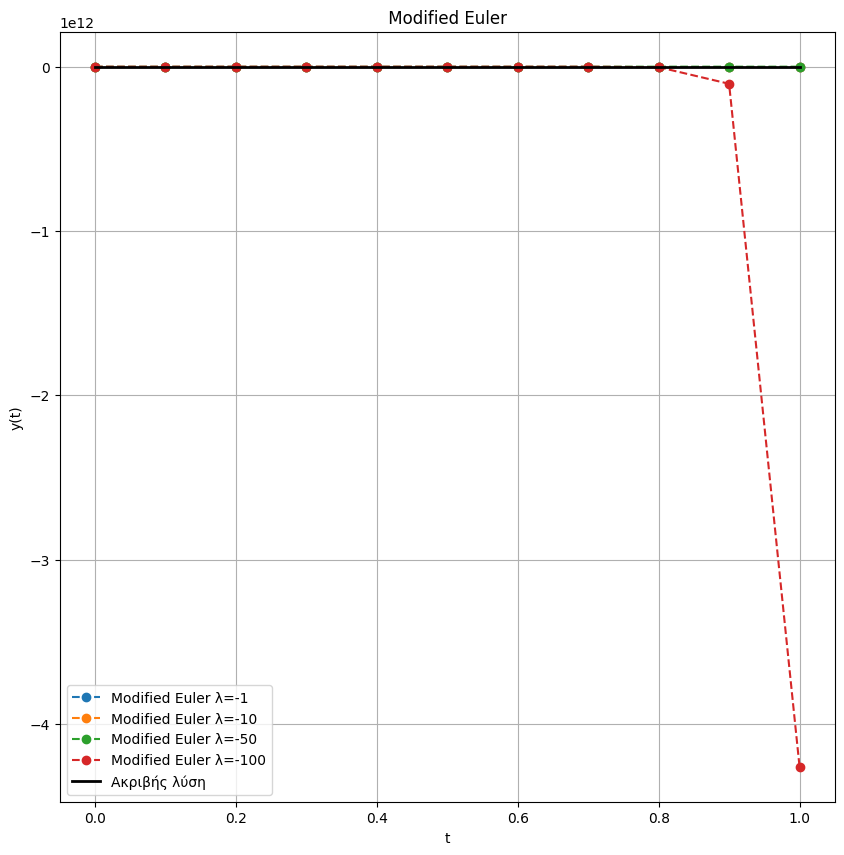

In [21]:
import numpy as np
import matplotlib.pyplot as plt


# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)


def Modified_Euler(f, t0, T, y0, N):

  tnodes = np.linspace(t0,T,N+1) # Uniform partition with N nodes
  h = tnodes[1] - tnodes[0]
  #print(tnodes)
  yn = np.zeros(N+1)
  yn[0] = y0

  for i in range(N):
    tn = tnodes[i]
    kn1 = f(tn, yn[i]) #kn1 = f(t^n, y^n)
    kn2 = f(tn+0.5*h, yn[i]+0.5*h*kn1)
    yn[i+1] = yn[i] + h*kn2

  return tnodes, yn

# -------------------------------
# Παράμετροι και διάγραμμα
# -------------------------------
t0 = 0.0
T  = 1.0
y0 = 1.0
N  = 10 # N =T-t0/h με h=0,1
lambdas = [-1, -10, -50, -100]


plt.figure(figsize=(10,10))
for lam in lambdas:
    def f(t, y):
        return lam*y + (1-lam)*np.cos(t) - (1+lam)*np.sin(t)
    t_list, y_num = Modified_Euler(f, t0, T, y0, N)
    plt.plot(t_list, y_num, marker='o', linestyle='--', label=f'Modified Euler λ={lam}')
# Ακριβής λύση
t_fine = np.linspace(t0, T, 200)
plt.plot(t_fine, y_exact(t_fine), 'k', linewidth=2, label='Ακριβής λύση')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title(' Modified Euler ')
plt.grid(True)
plt.legend()
plt.show()

#to l = -100 einai ektos diasthmatos gia ayto exei megalh apoklhsh
                     # −1 < hλ < 0


In [22]:
import numpy as np
import pandas as pd

# Ακριβής λύση
def y_exact(t):
    return np.cos(t) + np.sin(t)

# Παράμετροι
y0 = 1.0
lambdas = [-1, -10, -50, -100]
hs = [0.1, 0.05, 0.025, 0.001]
times_to_check = [0.2, 0.4, 0.6, 0.8, 1.0]  # Προσαρμοσμένα για T=1
rows = []

for lam in lambdas:
    for t_val in times_to_check:
        row = {"λ": lam, "t": t_val}
        for h in hs:
            N = int(t_val / h)
            t_list, y_num = Modified_Euler(f, t0, T, y0, N)
            error = np.abs(y_num[-1] - y_exact(t_val))
            row[f"Error h={h}"] = error
        rows.append(row)

# Δημιουργία DataFrame
df = pd.DataFrame(rows)
df.style.set_caption("Σφάλματα με Modified Euler")
print(df.to_latex(index=False, float_format="%.2e"))

\begin{tabular}{rrrrrr}
\toprule
λ & t & Error h=0.1 & Error h=0.05 & Error h=0.025 & Error h=0.001 \\
\midrule
-1 & 2.00e-01 & 1.74e-01 & 1.96e-01 & 2.01e-01 & 2.03e-01 \\
-1 & 4.00e-01 & 6.45e-02 & 6.97e-02 & 7.09e-02 & 7.13e-02 \\
-1 & 6.00e-01 & 1.25e-02 & 9.05e-03 & 8.39e-03 & 8.21e-03 \\
-1 & 8.00e-01 & 3.39e-02 & 3.27e-02 & 3.24e-02 & 3.23e-02 \\
-1 & 1.00e+00 & 1.02e-03 & 2.50e-04 & 6.19e-05 & 9.80e-08 \\
-10 & 2.00e-01 & 1.41e+00 & 1.60e-02 & 1.96e-01 & 2.03e-01 \\
-10 & 4.00e-01 & 1.48e-01 & 6.41e-02 & 7.03e-02 & 7.13e-02 \\
-10 & 6.00e-01 & 7.13e-02 & 1.09e-02 & 8.63e-03 & 8.21e-03 \\
-10 & 8.00e-01 & 3.95e-02 & 3.33e-02 & 3.25e-02 & 3.23e-02 \\
-10 & 1.00e+00 & 3.50e-03 & 5.86e-04 & 1.25e-04 & 1.76e-07 \\
-50 & 2.00e-01 & 2.43e+02 & 3.04e+04 & 1.63e+06 & 2.03e-01 \\
-50 & 4.00e-01 & 3.04e+04 & 1.63e+06 & 1.01e+04 & 7.13e-02 \\
-50 & 6.00e-01 & 1.49e+05 & 1.17e+06 & 1.74e-01 & 8.21e-03 \\
-50 & 8.00e-01 & 1.63e+06 & 1.01e+04 & 3.31e-02 & 3.23e-02 \\
-50 & 1.00e+00 & 1.68e+06

\begin{table}[h!]
\centering
\begin{tabular}{c}
The Modified Euler Method  \\
\end{tabular}
\begin{tabular}{rrrrrr}
\toprule
$\lambda$ & $t$ & Error $h=0.1$ & Error $h=0.05$ & Error $h=0.025$ & Error $h=0.001$ \\
\midrule
-1 & 2 & 1.74e-01 & 1.96e-01 & 2.01e-01 & 2.03e-01 \\
-1 & 4 & 6.45e-02 & 6.97e-02 & 7.09e-02 & 7.13e-02 \\
-1 & 6 & 1.25e-02 & 9.05e-03 & 8.39e-03 & 8.21e-03 \\
-1 & 8 & 3.39e-02 & 3.27e-02 & 3.24e-02 & 3.23e-02 \\
-1 & 10 & 1.02e-03 & 2.50e-04 & 6.19e-05 & 9.80e-08 \\
\midrule
-10 & 2 & 1.41e+00 & 1.60e-02 & 1.96e-01 & 2.03e-01 \\
-10 & 4 & 1.48e-01 & 6.41e-02 & 7.03e-02 & 7.13e-02 \\
-10 & 6 & 7.13e-02 & 1.09e-02 & 8.63e-03 & 8.21e-03 \\
-10 & 8 & 3.95e-02 & 3.33e-02 & 3.25e-02 & 3.23e-02 \\
-10 & 10 & 3.50e-03 & 5.86e-04 & 1.25e-04 & 1.76e-07 \\
\midrule
-50 & 2 & 2.43e+02 & 3.04e+04 & 1.63e+06 & 2.03e-01 \\
-50 & 4 & 3.04e+04 & 1.63e+06 & 1.01e+04 & 7.13e-02 \\
-50 & 6 & 1.49e+05 & 1.17e+06 & 1.74e-01 & 8.21e-03 \\
-50 & 8 & 1.63e+06 & 1.01e+04 & 3.31e-02 & 3.23e-02 \\
-50 & 10 & 1.68e+06 & 2.21e+01 & 2.91e-04 & 1.78e-07 \\
\midrule
-100 & 2 & 2.02e+03 & 4.89e+06 & 1.47e+11 & 2.03e-01 \\
-100 & 4 & 4.89e+06 & 1.47e+11 & 6.96e+14 & 7.13e-02 \\
-100 & 6 & 1.11e+08 & 1.61e+13 & 2.39e+14 & 8.21e-03 \\
-100 & 8 & 1.47e+11 & 6.96e+14 & 2.77e+10 & 3.23e-02 \\
-100 & 10 & 4.26e+12 & 8.17e+14 & 8.82e+04 & 1.82e-07 \\
\bottomrule
\end{tabular}
\caption{Errors for different values of $\lambda$ and step sizes $h$.}
\end{table}

